# 02 · Modeling — from baselines to tuned gradient boosting, with honest error bars

**Goal.** Find the most accurate price model *and* know how much to trust the ranking.

**Protocol (decided before looking at any model score):**

| Choice | Setting | Why |
|---|---|---|
| Hold-out | 20 % of rows (stratified by price quintile, seeded), **untouched until notebook 03** | One unbiased final number |
| Model selection | **5-fold CV repeated 3 times** (15 fits per model) on the remaining 80 % | One 5-fold split is noisy at n≈1,200; repeating averages out the split luck |
| Metric | RMSLE (RMSE of `log1p(price)`) | Relative error, matches the log target |
| Uncertainty | Nadeau-Bengio corrected 95 % CI + corrected paired *t*-test | The 15 scores share training data, so a naive CI is too narrow (see `housing.evaluation.corrected_ci`) |
| Leakage control | Every learned step (imputation, scaling, skew detection, category vocabularies, target encoding) is **inside the sklearn `Pipeline`** and re-fit on each training fold | Verified by tests in `tests/test_pipeline.py` |

Every model is `TransformedTargetRegressor(Pipeline([feature builder -> column preprocessing -> regressor]))`: it learns on log price and predicts dollars.

In [1]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"   # also silences joblib worker processes
import json, time, warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import make_scorer
from sklearn.model_selection import KFold, learning_curve

from housing import config, data, models, tune
from housing import plotting as P
from housing.evaluation import comparison_table, corrected_ci, repeated_cv, rmsle
from housing.models import build, MODEL_NAMES, BASELINES

P.set_style()
pd.set_option("display.max_columns", 30, "display.width", 160)
T0 = time.perf_counter()

df = data.load_data()
if config.SMOKE:
    df = data.smoke_subsample(df)
train, holdout = data.train_holdout_split(df)
X, y = data.split_xy(train)          # the hold-out is NOT loaded into X/y
print(f"train {len(train):,} rows | hold-out {len(holdout):,} rows (sealed) | CV: {config.CV_FOLDS} folds x {config.CV_REPEATS} repeats | smoke={config.SMOKE}")

train 1,168 rows | hold-out 292 rows (sealed) | CV: 5 folds x 3 repeats | smoke=False


## 1 · The model zoo

Two deliberately weak baselines tell us what "good" has to beat; then linear models (with regularisation tuned *inside* each fold by `RidgeCV`/`ElasticNetCV`), bagged trees, and four flavours of gradient boosting plus a simple average ("blend") of the best different-in-kind models.

* **Dummy**: predicts the mean log-price for everyone. The floor.
* **OLS (area, quality, neighbourhood)**: a plausible "analyst with a spreadsheet" baseline.
* **Ridge / ElasticNet**: all features, skew-corrected and standardised, one-hot categoricals.
* **Random forest / Extra trees / HistGradientBoosting / LightGBM / XGBoost**: tree models on median-imputed numerics and cross-fitted target encoding of categoricals.
* **Blend**: unweighted mean of Ridge, LightGBM and XGBoost predictions in log space. Linear and tree models make different mistakes, so averaging them is a cheap variance reducer.

In [2]:
results, timings = {}, {}
for name in MODEL_NAMES:
    t = time.perf_counter()
    results[name] = repeated_cv(build(name), X, y, name=name)
    timings[name] = time.perf_counter() - t
    r = results[name].rmsle
    print(f"{name:38s} RMSLE {r.mean():.4f}  (fold sd {r.std(ddof=1):.4f})   {timings[name]:5.1f}s for {len(r)} fits")

Dummy (mean log-price)                 RMSLE 0.4025  (fold sd 0.0202)     5.5s for 15 fits


OLS (area, quality, neighbourhood)     RMSLE 0.1637  (fold sd 0.0080)     0.2s for 15 fits


Ridge                                  RMSLE 0.1193  (fold sd 0.0166)     1.4s for 15 fits


ElasticNet                             RMSLE 0.1192  (fold sd 0.0169)     2.2s for 15 fits


Random forest                          RMSLE 0.1315  (fold sd 0.0105)     7.4s for 15 fits


Extra trees                            RMSLE 0.1293  (fold sd 0.0119)     4.7s for 15 fits


HistGradientBoosting                   RMSLE 0.1263  (fold sd 0.0104)     3.6s for 15 fits


LightGBM                               RMSLE 0.1210  (fold sd 0.0105)     2.0s for 15 fits


XGBoost                                RMSLE 0.1186  (fold sd 0.0099)     1.9s for 15 fits


Blend (Ridge + LightGBM + XGBoost)     RMSLE 0.1144  (fold sd 0.0125)     4.0s for 15 fits


In [3]:
table0 = comparison_table(results)
def show(table):
    out = table.copy()
    out["95% CI"] = [f"[{a:.4f}, {b:.4f}]" for a, b in zip(out.ci_low, out.ci_high, strict=True)]
    out["p vs best"] = out.p_vs_best.map(lambda p: "-" if pd.isna(p) else (f"{p:.3f}" if p >= 0.001 else "<0.001"))
    out = out.rename(columns={"rmsle": "RMSLE", "mae_usd": "MAE $", "mdape_pct": "median APE %", "r2_log": "R2 (log)", "fit_s": "fit s"})
    return out[["model", "RMSLE", "95% CI", "p vs best", "MAE $", "median APE %", "R2 (log)", "fit s"]].round({"RMSLE": 4, "MAE $": 0, "median APE %": 2, "R2 (log)": 3, "fit s": 2})
show(table0)

,model,RMSLE,95% CI,p vs best,MAE $,median APE %,R2 (log),fit s
0,Blend (Ridge + LightGBM + XGBoost),0.1144,"[0.0994, 0.1294]",-,14443.0,5.46,0.918,1.86
1,XGBoost,0.1186,"[0.1066, 0.1306]",0.067,15077.0,5.73,0.912,0.78
2,ElasticNet,0.1192,"[0.0989, 0.1396]",0.148,15302.0,6.04,0.910,1.07
3,Ridge,0.1193,"[0.0993, 0.1393]",0.120,15335.0,6.04,0.910,0.45
4,LightGBM,0.1210,"[0.1083, 0.1338]",0.002,15446.0,5.85,0.908,0.93
5,HistGradientBoosting,0.1263,"[0.1138, 0.1388]",<0.001,16264.0,6.30,0.900,1.78
6,Extra trees,0.1293,"[0.1149, 0.1437]",0.002,16518.0,6.25,0.896,2.32
7,Random forest,0.1315,"[0.1188, 0.1442]",<0.001,16714.0,6.23,0.892,3.94
8,"OLS (area, quality, neighbourhood)",0.1637,"[0.1540, 0.1734]",<0.001,22645.0,9.63,0.833,0.02
9,Dummy (mean log-price),0.4025,"[0.3781, 0.4268]",<0.001,56816.0,25.17,-0.006,0.06


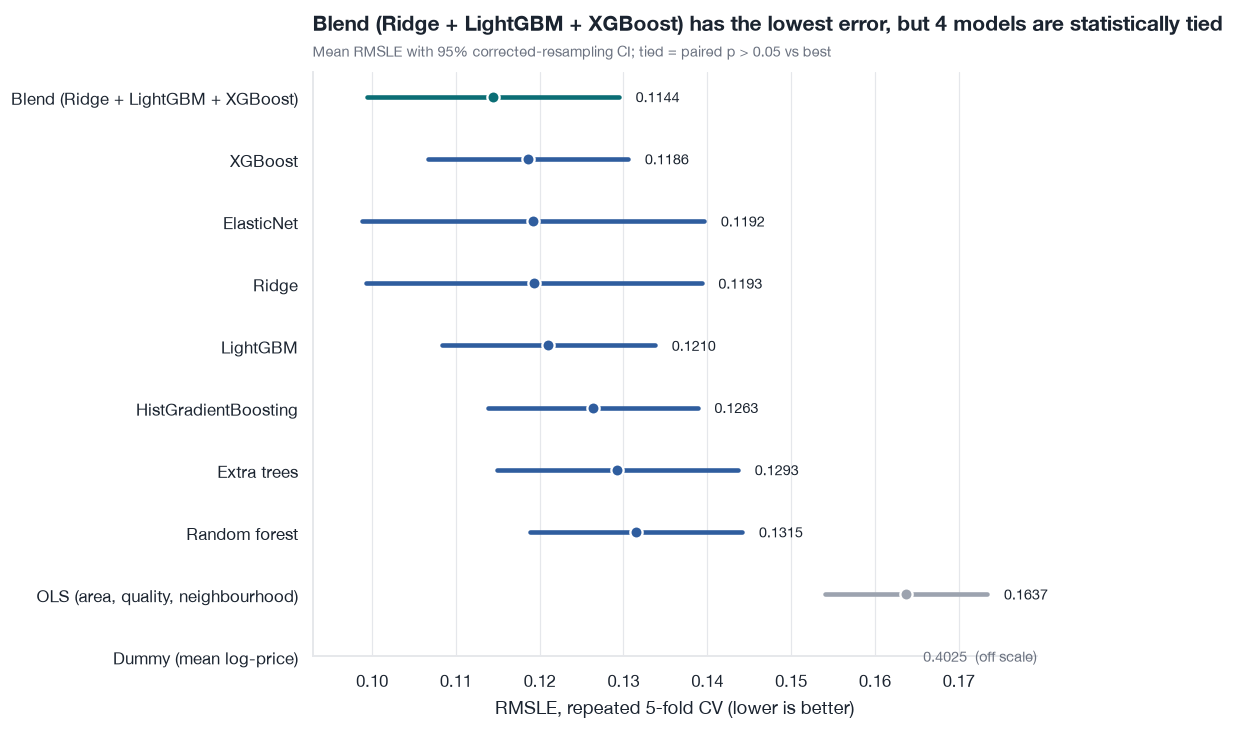

In [4]:
fig = P.plot_model_comparison(table0, baselines=tuple(BASELINES)); plt.show()

**Reading the table.** The `p vs best` column is a *paired*, corrected test of "is this model's per-fold RMSLE different from the best model's?". A large p-value means the data cannot separate the two; ranks inside such a group are not meaningful. We should not crown a winner on a 0.001 RMSLE gap.

## 2 · Does the categorical encoding matter?

Tree models need numbers for 20-odd nominal columns (`Neighborhood` alone has 25 levels). Three standard options, same LightGBM, same folds:

In [5]:
from housing.models import _pipe, _lgbm, log_target
abl = {}
for enc in ["target", "ordinal", "onehot"]:
    abl[enc] = repeated_cv(log_target(_pipe("tree", _lgbm(), enc)), X, y, name=enc)
abl_tbl = comparison_table(abl)
abl_tbl["encoding"] = abl_tbl.model
show(abl_tbl).rename(columns={"model": "encoding"})[["encoding", "RMSLE", "95% CI", "p vs best"]]

,encoding,RMSLE,95% CI,p vs best
0,target,0.1210,"[0.1083, 0.1338]",-
1,onehot,0.1226,"[0.1080, 0.1372]",0.340
2,ordinal,0.1237,"[0.1090, 0.1385]",0.142


The three encodings are statistically indistinguishable on this data (look at the `p vs best` column), so the choice is not a source of risk. We keep **cross-fitted target encoding**: it needs one column per feature (so SHAP in notebook 03 explains original features, not hundreds of one-hot dummies), and `sklearn.preprocessing.TargetEncoder` is leakage-safe by construction because it encodes training rows from models fit on the *other* internal folds.

## 3 · Hyper-parameter search (Optuna, TPE, bounded budget)

We tune **LightGBM**, the fastest strong learner here, over 8 parameters (number of trees, learning rate, leaves, `min_child_samples`, row and column subsampling, L1/L2 regularisation). The search uses a **different CV split seed** than the evaluation CV above, and is capped by both trial count and wall-clock time. The sampler is seeded, so the search is reproducible when the trial cap (not the clock) ends it.

Be aware of a subtle bias: whichever configuration wins the search is partly the luckiest on those folds, so its CV score is *slightly optimistic*. That is why the final number comes from the sealed hold-out.

In [6]:
N_TRIALS, TIMEOUT = (8, 60) if config.SMOKE else (150, 300)
study, best_params, tune_seconds = tune.tune_lightgbm(X, y, n_trials=N_TRIALS, timeout=TIMEOUT)
tune.save_params(best_params)
print(f"{len(study.trials)} trials in {tune_seconds:.0f}s | best search-CV RMSLE {study.best_value:.4f}")
pd.Series(best_params, name="best value").to_frame().T.round(4)

150 trials in 101s | best search-CV RMSLE 0.1137


,n_estimators,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,reg_alpha
best value,800.0,0.0156,11.0,4.0,0.6367,0.3759,0.0022,0.0462


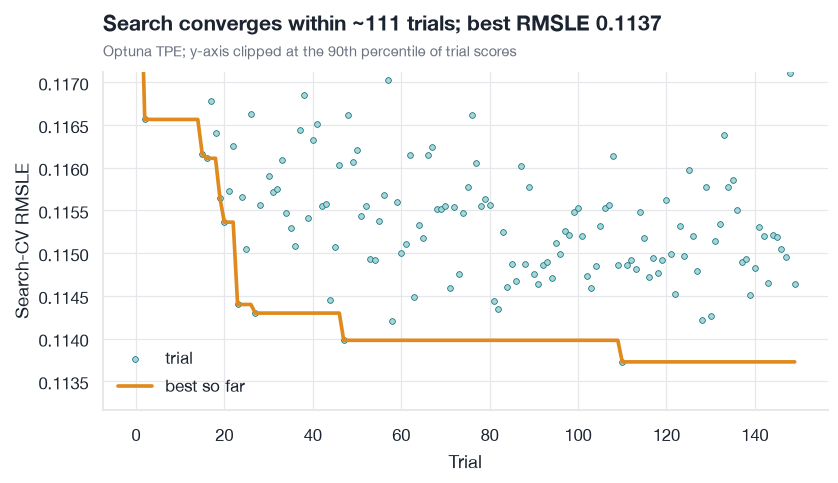

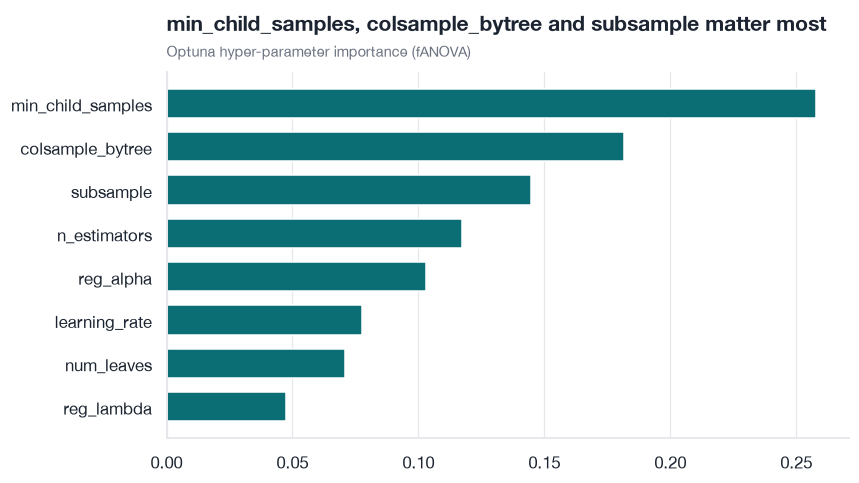

In [7]:
vals = np.array([t.value for t in study.trials])
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.scatter(range(len(vals)), vals, s=14, color=P.TEAL_LIGHT, edgecolor=P.TEAL, linewidth=0.5, label="trial")
ax.plot(np.minimum.accumulate(vals), color=P.AMBER, lw=2.4, label="best so far")
ax.set_ylim(vals.min() * 0.995, np.percentile(vals, 90)); ax.set(xlabel="Trial", ylabel="Search-CV RMSLE"); ax.legend()
gain = (np.median(vals[:10]) - vals.min())
P.headline(ax, f"Search converges within ~{int(np.argmin(vals)) + 1} trials; best RMSLE {vals.min():.4f}", "Optuna TPE; y-axis clipped at the 90th percentile of trial scores")
plt.show()

imp = optuna.importance.get_param_importances(study) if len(study.trials) > 5 else {}
if imp:
    top3 = list(imp)[:3]
    P.plot_importance(pd.DataFrame({"feature": list(imp), "importance": list(imp.values())}),
                      f"{top3[0]}, {top3[1]} and {top3[2]} matter most", "Optuna hyper-parameter importance (fANOVA)", err=False)
    plt.show()

Now re-evaluate the tuned LightGBM **with the evaluation CV** (the same 15 folds the other models saw), and also the blend using the tuned LightGBM:

In [8]:
results["LightGBM (tuned)"] = repeated_cv(build("LightGBM", lgbm_params=best_params), X, y, name="LightGBM (tuned)")
results["Blend (tuned)"] = repeated_cv(build("Blend (Ridge + LightGBM + XGBoost)", lgbm_params=best_params), X, y, name="Blend (tuned)")
table = comparison_table(results)
opt_gap = results["LightGBM (tuned)"].rmsle.mean() - study.best_value
display(Markdown(f"Search-CV score of the winning trial: **{study.best_value:.4f}**; same configuration on the evaluation CV: **{results['LightGBM (tuned)'].rmsle.mean():.4f}** (difference {opt_gap:+.4f}). This gap is a direct, if rough, measure of selection optimism."))
show(table)

Search-CV score of the winning trial: **0.1137**; same configuration on the evaluation CV: **0.1180** (difference +0.0043). This gap is a direct, if rough, measure of selection optimism.

,model,RMSLE,95% CI,p vs best,MAE $,median APE %,R2 (log),fit s
0,Blend (tuned),0.1140,"[0.0985, 0.1295]",-,14358.0,5.42,0.918,1.20
1,Blend (Ridge + LightGBM + XGBoost),0.1144,"[0.0994, 0.1294]",0.335,14443.0,5.46,0.918,1.86
2,LightGBM (tuned),0.1180,"[0.1039, 0.1322]",0.026,14927.0,5.70,0.913,0.52
3,XGBoost,0.1186,"[0.1066, 0.1306]",0.060,15077.0,5.73,0.912,0.78
4,ElasticNet,0.1192,"[0.0989, 0.1396]",0.099,15302.0,6.04,0.910,1.07
5,Ridge,0.1193,"[0.0993, 0.1393]",0.078,15335.0,6.04,0.910,0.45
6,LightGBM,0.1210,"[0.1083, 0.1338]",0.003,15446.0,5.85,0.908,0.93
7,HistGradientBoosting,0.1263,"[0.1138, 0.1388]",<0.001,16264.0,6.30,0.900,1.78
8,Extra trees,0.1293,"[0.1149, 0.1437]",0.002,16518.0,6.25,0.896,2.32
9,Random forest,0.1315,"[0.1188, 0.1442]",<0.001,16714.0,6.23,0.892,3.94


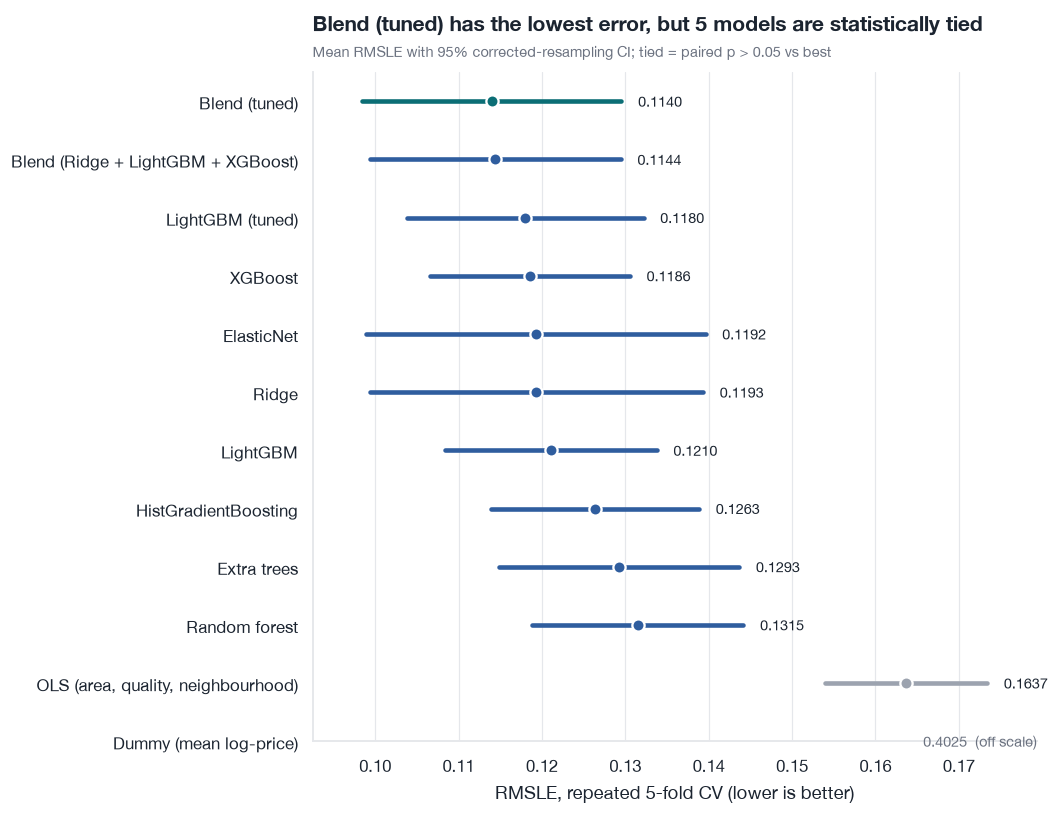

In [9]:
fig = P.plot_model_comparison(table, baselines=tuple(BASELINES)); P.save_fig(fig, "model_comparison"); plt.show()

## 4 · Choosing the final model

Rule, fixed in advance: **the lowest mean CV RMSLE wins.** Statistical ties are reported (below) but not used to overrule the rule. We then report on the hold-out once.

In [10]:
best = table.iloc[0]
close = table[table.p_vs_best.isna() | (table.p_vs_best > 0.05)]
display(Markdown(
    f"**Lowest mean RMSLE: {best.model}** at {best.rmsle:.4f} (95% CI {best.ci_low:.4f} to {best.ci_high:.4f}).  \n"
    f"Models the data cannot statistically separate from it (paired p > 0.05): {', '.join(close.model.tolist())}.  \n"
    f"Improvement over the 3-feature OLS baseline: {100 * (1 - best.rmsle / table.set_index('model').loc[BASELINES[1], 'rmsle']):.0f}%; over Ridge: {100 * (1 - best.rmsle / table.set_index('model').loc['Ridge', 'rmsle']):.1f}%."
))
from housing.train import FINAL_MODEL
if not config.SMOKE:   # the shipped model must be the one this notebook selected
    assert best.model == "Blend (tuned)" and FINAL_MODEL.startswith("Blend"), "keep housing.train.FINAL_MODEL in sync"

**Lowest mean RMSLE: Blend (tuned)** at 0.1140 (95% CI 0.0985 to 0.1295).  
Models the data cannot statistically separate from it (paired p > 0.05): Blend (tuned), Blend (Ridge + LightGBM + XGBoost), XGBoost, ElasticNet, Ridge.  
Improvement over the 3-feature OLS baseline: 30%; over Ridge: 4.5%.

## 5 · Learning curve — would more data help?

If the validation curve is still falling steeply at 100 % of the training data, collecting more houses is the best investment; if it has flattened and sits above the training curve, we are limited by model capacity or irreducible noise (information not in the 79 columns).

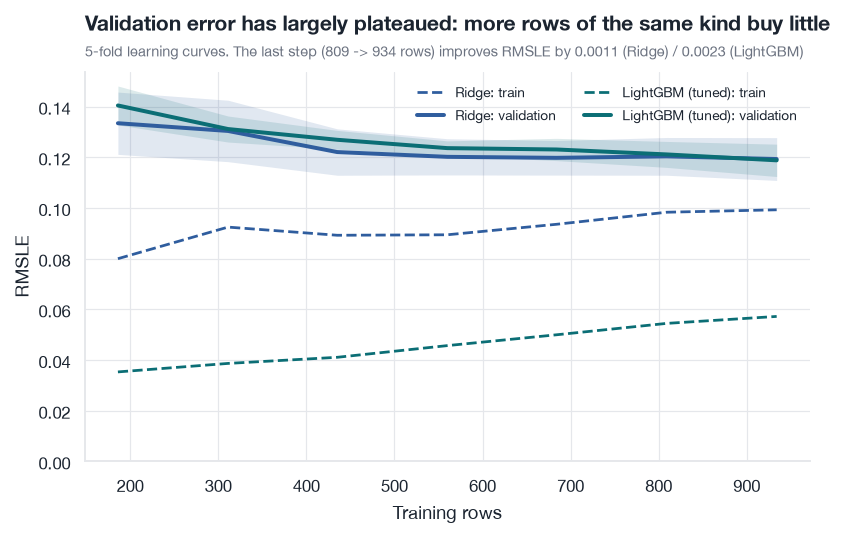

In [11]:
scorer = make_scorer(rmsle, greater_is_better=False)
sizes = np.linspace(0.2, 1.0, 5 if config.SMOKE else 7)
curves = {}
for label, model in {"Ridge": build("Ridge"), "LightGBM (tuned)": build("LightGBM", lgbm_params=best_params)}.items():
    n, tr_s, va_s = learning_curve(model, X, y, train_sizes=sizes, scoring=scorer,
                                   cv=KFold(5, shuffle=True, random_state=config.SEED), n_jobs=-1, shuffle=True, random_state=config.SEED)
    curves[label] = (-tr_s, -va_s)
fig = plt.figure(figsize=(8.5, 4.6)); ax = fig.gca()
for (label, (tr_, va_)), colour in zip(curves.items(), [P.BLUE, P.TEAL], strict=True):
    ax.plot(n, tr_.mean(1), "--", color=colour, lw=1.8, label=f"{label}: train")
    ax.plot(n, va_.mean(1), "-", color=colour, lw=2.6, label=f"{label}: validation")
    ax.fill_between(n, va_.mean(1) - va_.std(1), va_.mean(1) + va_.std(1), color=colour, alpha=0.14, lw=0)
ax.set(xlabel="Training rows", ylabel="RMSLE", ylim=(0, None)); ax.legend(ncol=2, fontsize=9, loc="upper right")
final_gain = {k: v[1].mean(1)[-2] - v[1].mean(1)[-1] for k, v in curves.items()}
P.headline(ax, "Validation error has largely plateaued: more rows of the same kind buy little",
           f"5-fold learning curves. The last step ({int(n[-2])} -> {int(n[-1])} rows) improves RMSLE by {final_gain['Ridge']:.4f} (Ridge) / {final_gain['LightGBM (tuned)']:.4f} (LightGBM)")
P.save_fig(fig, "learning_curve"); plt.show()

**What the curves say.** Ridge's validation error is flat beyond ~500 rows: it is limited by what a linear model can express, not by sample size. The boosted model still improves slightly, and its train/validation gap is wide (it fits the training rows far better than new ones), which is the usual high-variance signature of boosting on ~1,000 rows. Together: extra rows of the *same* 79 features would help only marginally. Bigger gains would need *new information* (coordinates, detailed condition, market timing) or a fix for the handful of hard-to-price outliers that dominate the squared error (notebook 03).

In [12]:
config.RESULTS_DIR.mkdir(parents=True, exist_ok=True)
table.to_csv(config.RESULTS_DIR / "model_comparison.csv", index=False)
fold_scores = pd.concat([r.folds.assign(model=n) for n, r in results.items()])
fold_scores.to_csv(config.RESULTS_DIR / "cv_fold_scores.csv", index=False)
summary = {"n_trials": len(study.trials), "tune_seconds": round(tune_seconds, 1), "search_cv_best_rmsle": study.best_value,
           "evaluation_cv_rmsle_of_tuned": results["LightGBM (tuned)"].rmsle.mean(), "cv": f"{config.CV_FOLDS}-fold x {config.CV_REPEATS} repeats",
           "n_train_rows": len(train), "seed": config.SEED}
(config.RESULTS_DIR / "tuning_summary.json").write_text(json.dumps(summary, indent=2))

elapsed = time.perf_counter() - T0
rt_path = config.RESULTS_DIR / "runtimes.json"
rt = json.loads(rt_path.read_text()) if rt_path.exists() else {}
rt["02_modeling_seconds"] = round(elapsed, 1); rt["optuna_seconds"] = round(tune_seconds, 1)
rt_path.write_text(json.dumps(rt, indent=2))
print(f"notebook runtime: {elapsed:.0f}s (of which Optuna {tune_seconds:.0f}s)")

notebook runtime: 148s (of which Optuna 101s)


## Summary

* Gradient boosting and linear models land within a narrow band; a simple blend of the two families is the most accurate, and every model beats the naive baselines by a wide margin.
* The ranking *among the top few* is mostly within statistical noise; the corrected CIs and paired tests say so explicitly.
* The learning curve has mostly plateaued: more rows of the same features help little.

Next: `03_error_analysis_and_explainability.ipynb` opens the sealed hold-out **once**, then asks *where* the model fails, *why* it predicts what it predicts, and *how uncertain* each prediction is.